### Machine failure prediction

Ref: https://www.kaggle.com/datasets/dineshmanikanta/machine-failure-predictions/

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from sklearn.utils import resample
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, StandardScaler, PowerTransformer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, accuracy_score, classification_report
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import BinaryCrossentropy
from tensorflow.keras.callbacks import EarlyStopping

# from tf_keras.models import Sequential
# from tf_keras.layers import Input, Dense, Dropout
# from tf_keras.optimizers import Adam
# from tf_keras.losses import BinaryCrossentropy
# from tf_keras.callbacks import EarlyStopping

2026-09-03 14:24:03.912808: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-09-03 14:24:05.209097: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT


In [2]:
# Define Seaborn theme parameters
theme_parameters =  {
    'axes.spines.right': False,
    'axes.spines.top': False,
    'grid.alpha':0.3,
    'axes.titlesize': 12,
    'figure.figsize': (12, 4),
}

sns.set_theme(style='whitegrid', palette=sns.color_palette('colorblind'), rc=theme_parameters)

In [31]:
df = pd.read_csv('machine failure 2.csv')

In [34]:
df[df['Machine failure']==1].iloc[3]

id                            236
Product ID                 L55926
Type                            L
Air temperature [K]         297.3
Process temperature [K]     308.6
Rotational speed [rpm]       1258
Torque [Nm]                  61.8
Tool wear [min]               144
Machine failure                 1
TWF                             0
HDF                             0
PWF                             0
OSF                             1
RNF                             0
Name: 236, dtype: object

In [5]:
df.columns

Index(['id', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF',
       'RNF'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 136429 entries, 0 to 136428
Data columns (total 14 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   id                       136429 non-null  int64  
 1   Product ID               136429 non-null  object 
 2   Type                     136429 non-null  object 
 3   Air temperature [K]      136429 non-null  float64
 4   Process temperature [K]  136429 non-null  float64
 5   Rotational speed [rpm]   136429 non-null  int64  
 6   Torque [Nm]              136429 non-null  float64
 7   Tool wear [min]          136429 non-null  int64  
 8   Machine failure          136429 non-null  int64  
 9   TWF                      136429 non-null  int64  
 10  HDF                      136429 non-null  int64  
 11  PWF                      136429 non-null  int64  
 12  OSF                      136429 non-null  int64  
 13  RNF                      136429 non-null  int64  
dtypes: f

In [7]:
df.isnull().all().any()

False

<Axes: >

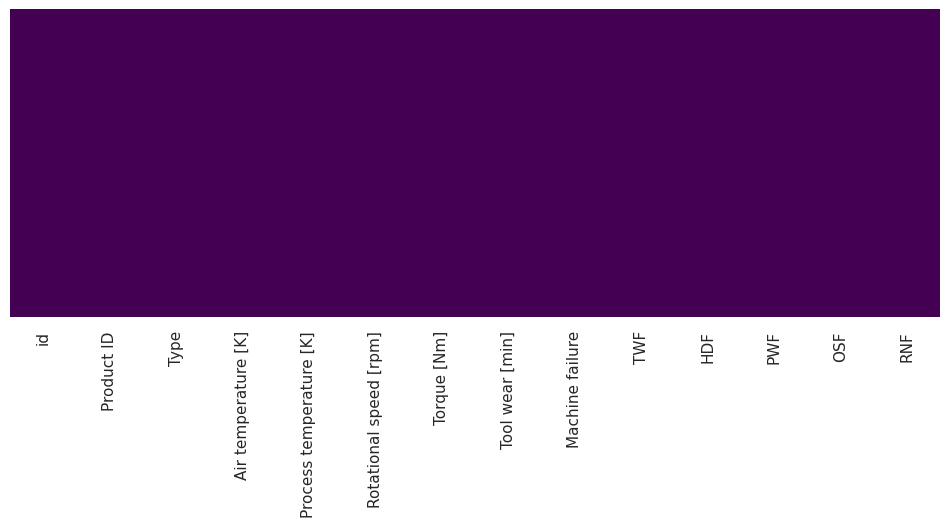

In [8]:
sns.heatmap(df.isnull(), yticklabels=False, cbar=False, cmap='viridis')

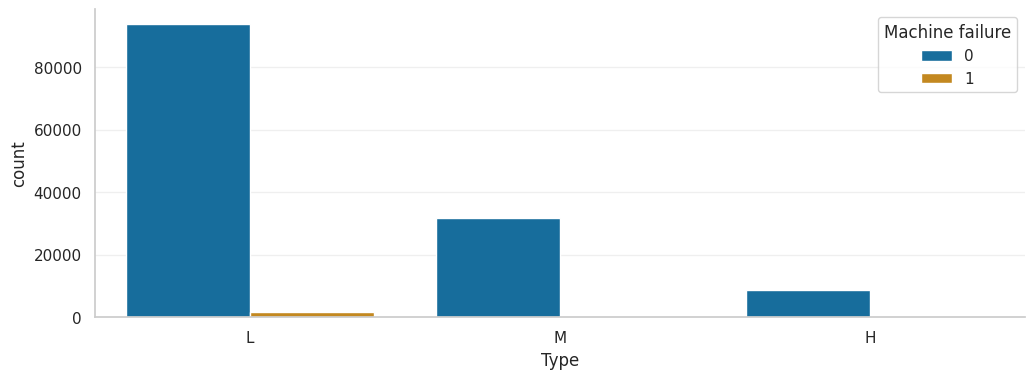

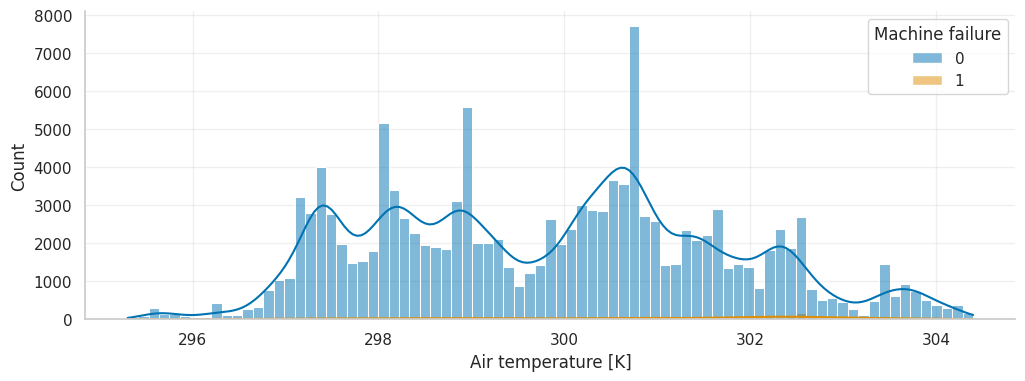

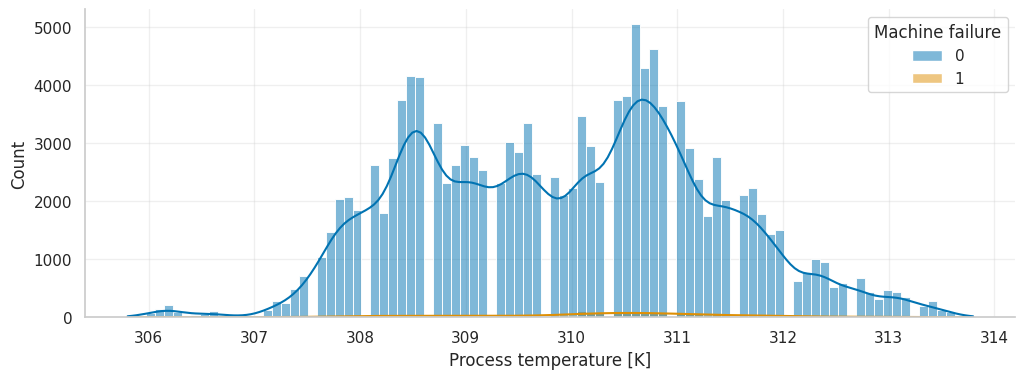

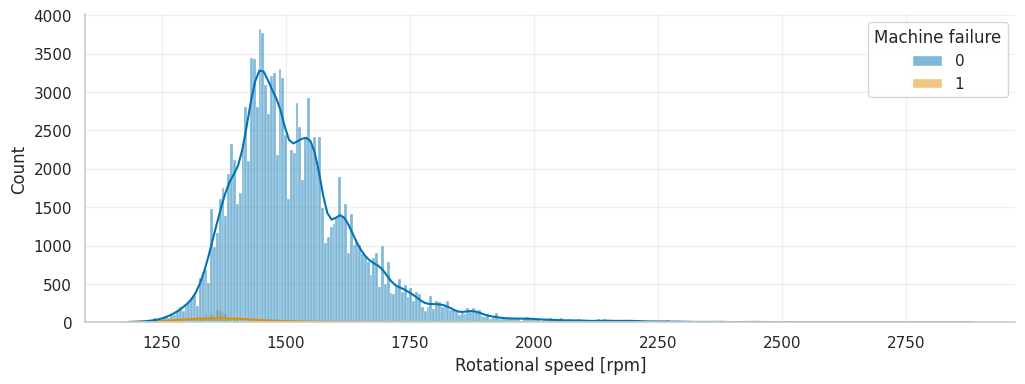

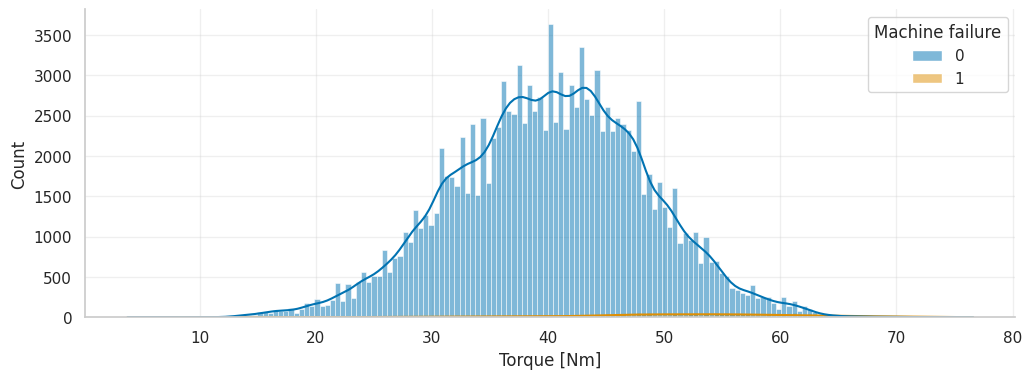

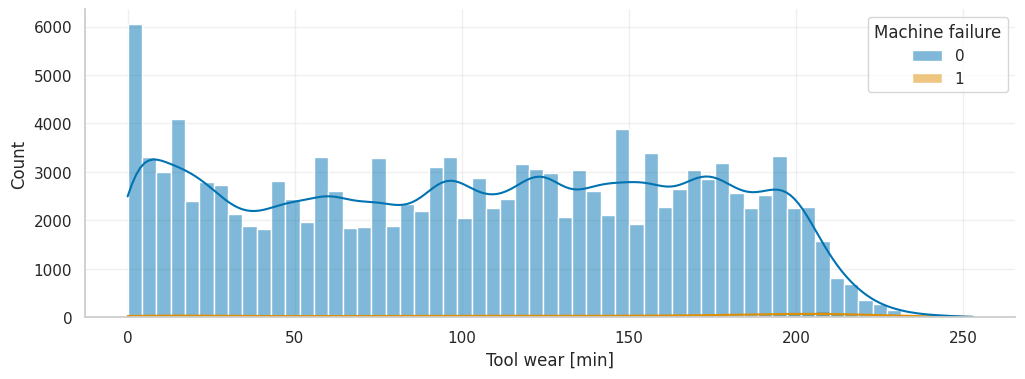

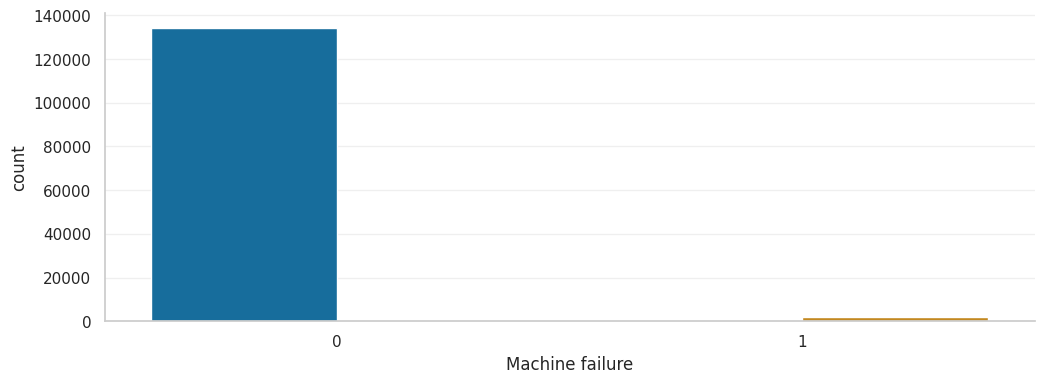

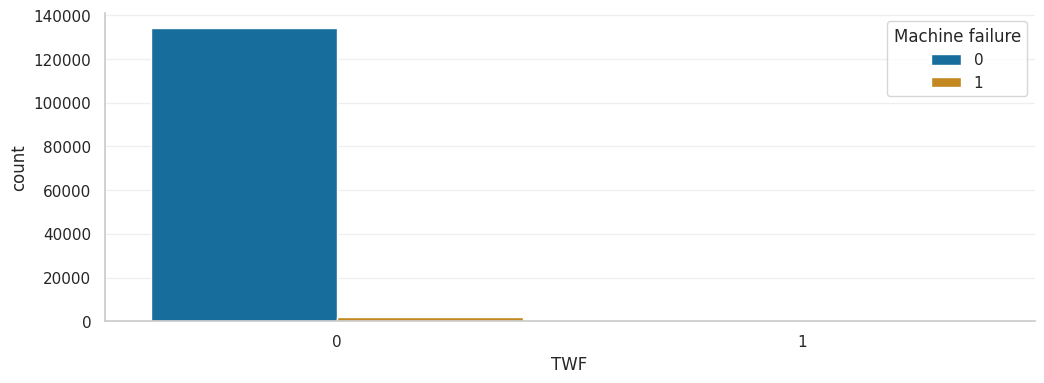

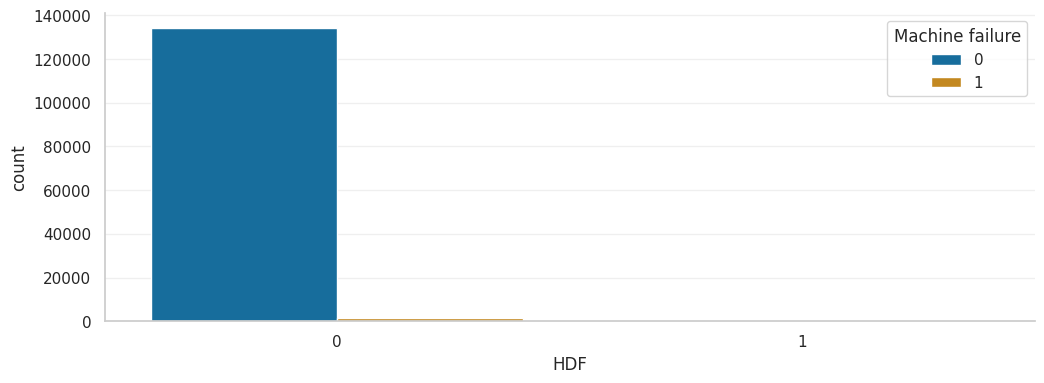

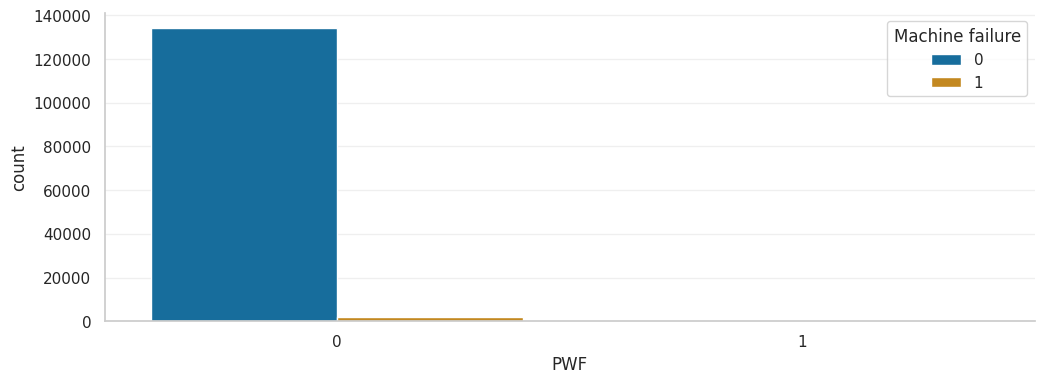

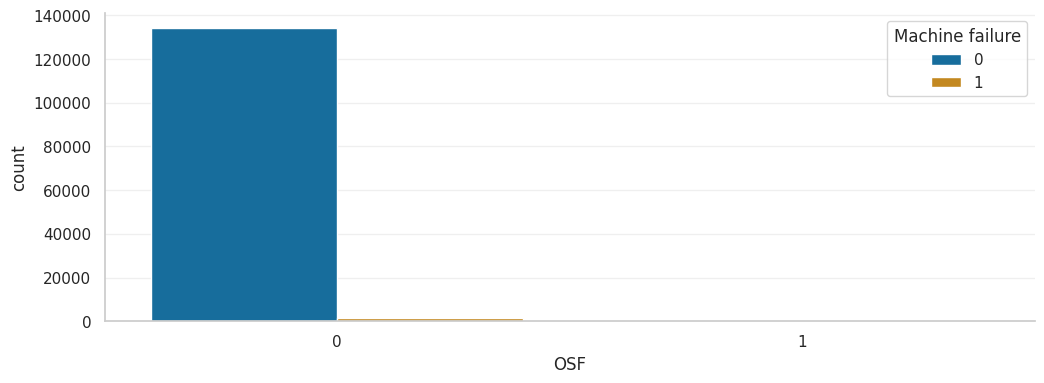

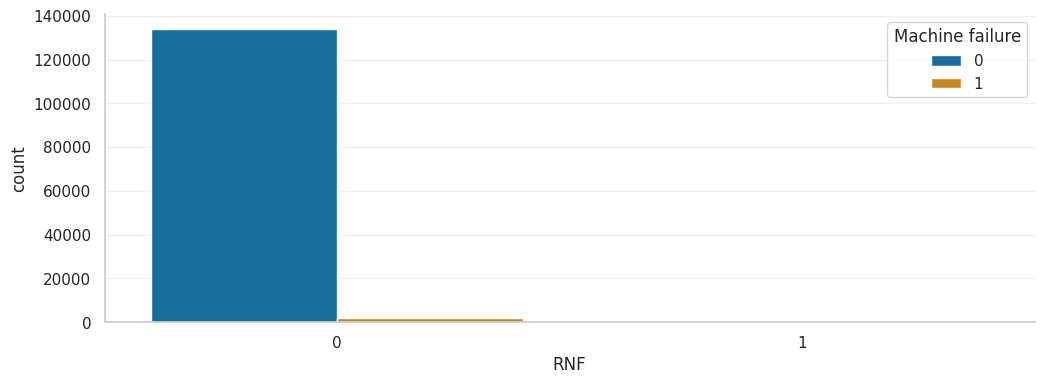

In [9]:
# Visualise distribution of features
# Method #1

cols  = df.columns
for i in cols[2:]:
    if(df[i].dtype.kind in 'if' and df[i].value_counts().count()>=5):
        sns.histplot(data=df,x=i,hue='Machine failure',kde=True)
    else:
        df[i] = df[i].astype(str)
        sns.countplot(data=df,x=i,hue="Machine failure",dodge=True)
    plt.show()

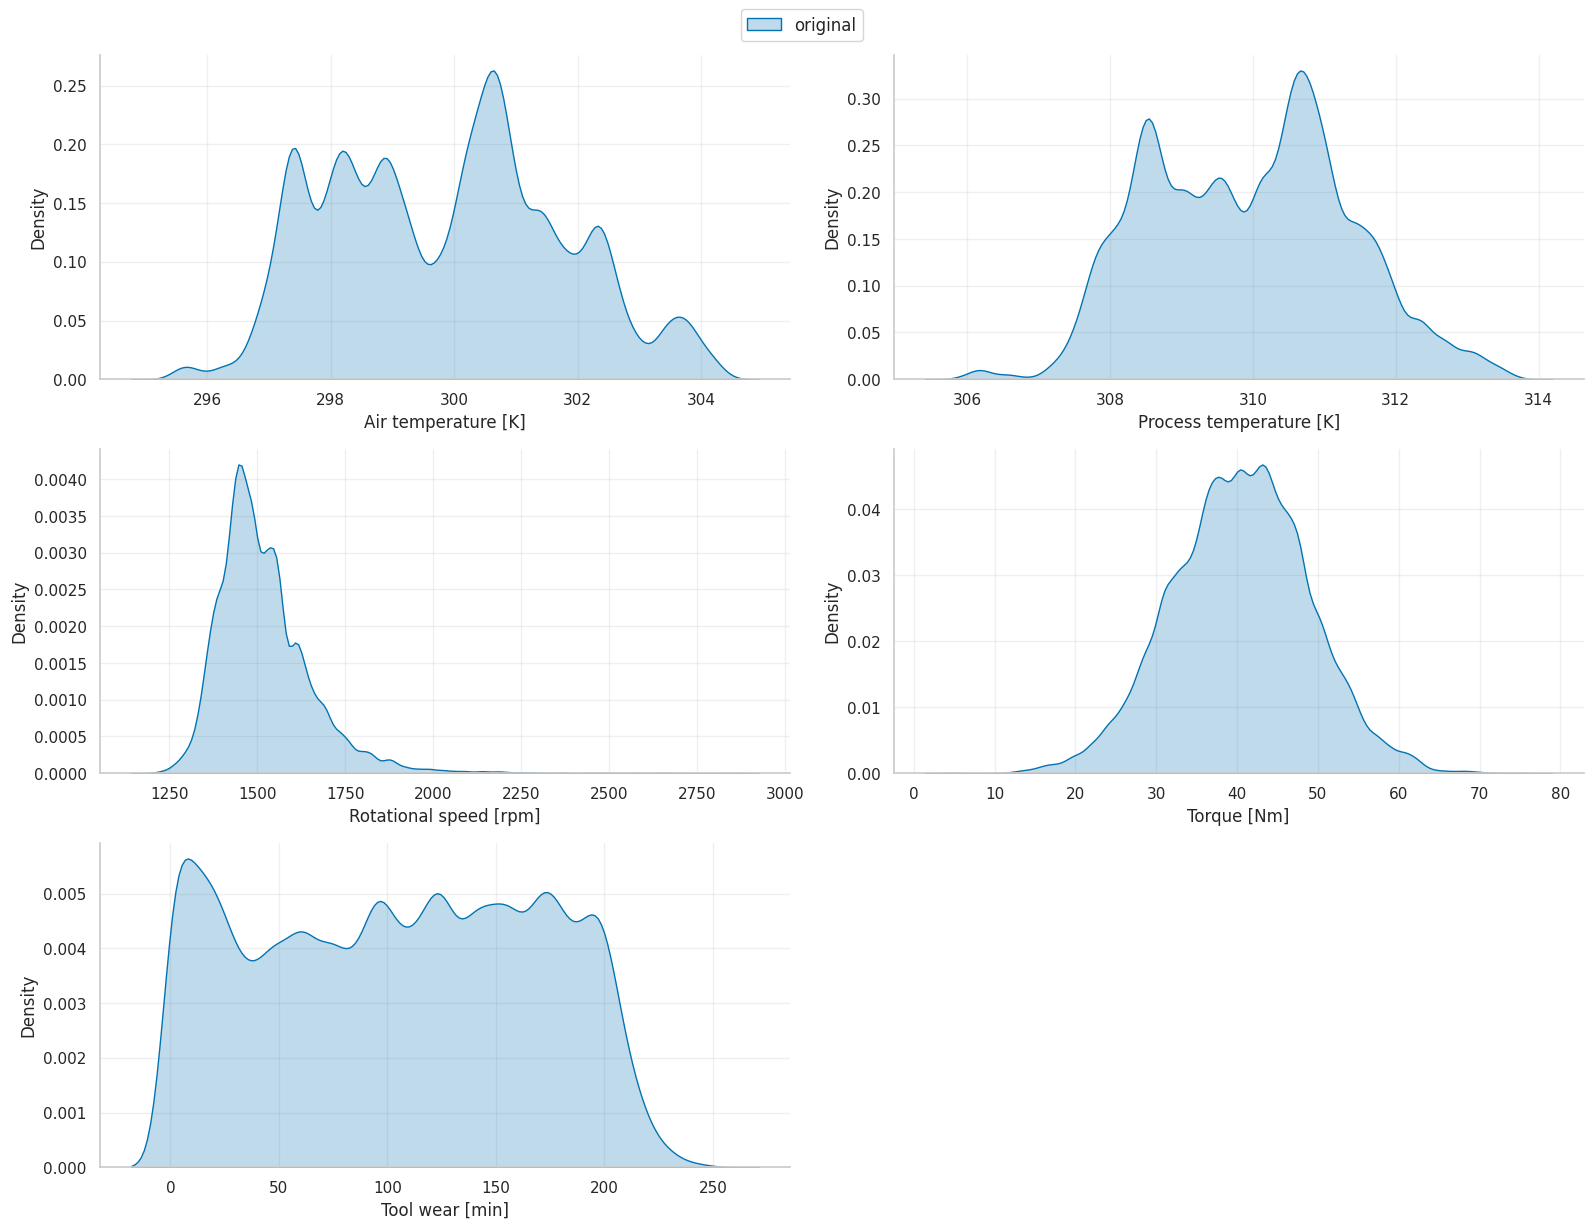

In [10]:
# Visualise distribution of features
# Method #2

fig, ax = plt.subplots(3,2, figsize=(16,12))
ax = ax.flatten()

# create a list to exclude categorical features and the label
excluded_cols = ['id', 'Product ID', 'Type', 'TWF', 'HDF', 'PWF', 'OSF',
       'RNF', 'Machine failure']
cols = df.drop(excluded_cols, axis=1).columns

for idx, col_name in enumerate(cols):
    sns.kdeplot(data=df[col_name], fill=True, ax=ax[idx], label='original')

    # Retrieve legend information
    handles = ax[idx].get_legend_handles_labels()[0]
    labels = ax[idx].get_legend_handles_labels()[1]
    ax[idx].legend().remove()

# Remove the empty subplots
fig.delaxes(ax[-1])

# Set the legend
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 1.03), fontsize=12, ncol=3)
plt.tight_layout()
plt.show()

<Axes: xlabel='Machine failure', ylabel='count'>

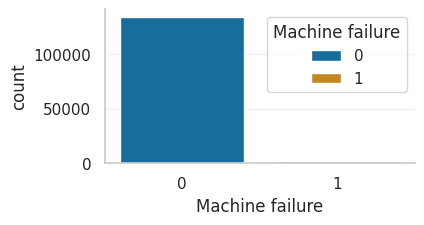

In [35]:
plt.subplots(figsize = (4,2))
sns.countplot(data=df, x='Machine failure', hue='Machine failure')

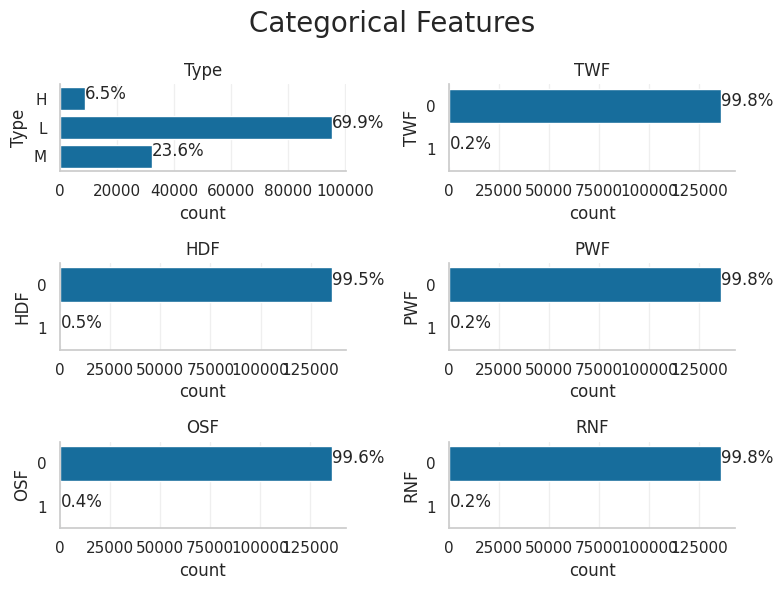

In [12]:
# Categorical Features
figure, ax = plt.subplots(3, 2, figsize=(8, 6))
ax = ax.flatten()

# Select the categorical columns for plotting
categorical_columns = ['Type', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']


for index, col_name in enumerate(categorical_columns):
    sns.countplot(data=df.sort_values(col_name), 
                  y=col_name,    # use y instead of x caused the plot to be drawn horizontally
                  ax=ax[index])

    ax[index].set_title(col_name)

    # Add percentage labels
    total = float(len(df[col_name]))
    for p in ax[index].patches:
        percentage = '{:.1f}%'.format(100 * p.get_width() / total)
        x = p.get_x() + p.get_width() + 0.1
        y = p.get_y() + p.get_height() / 2
        ax[index].annotate(percentage, (x, y))

plt.suptitle('Categorical Features', fontsize=20)    
    
plt.tight_layout()

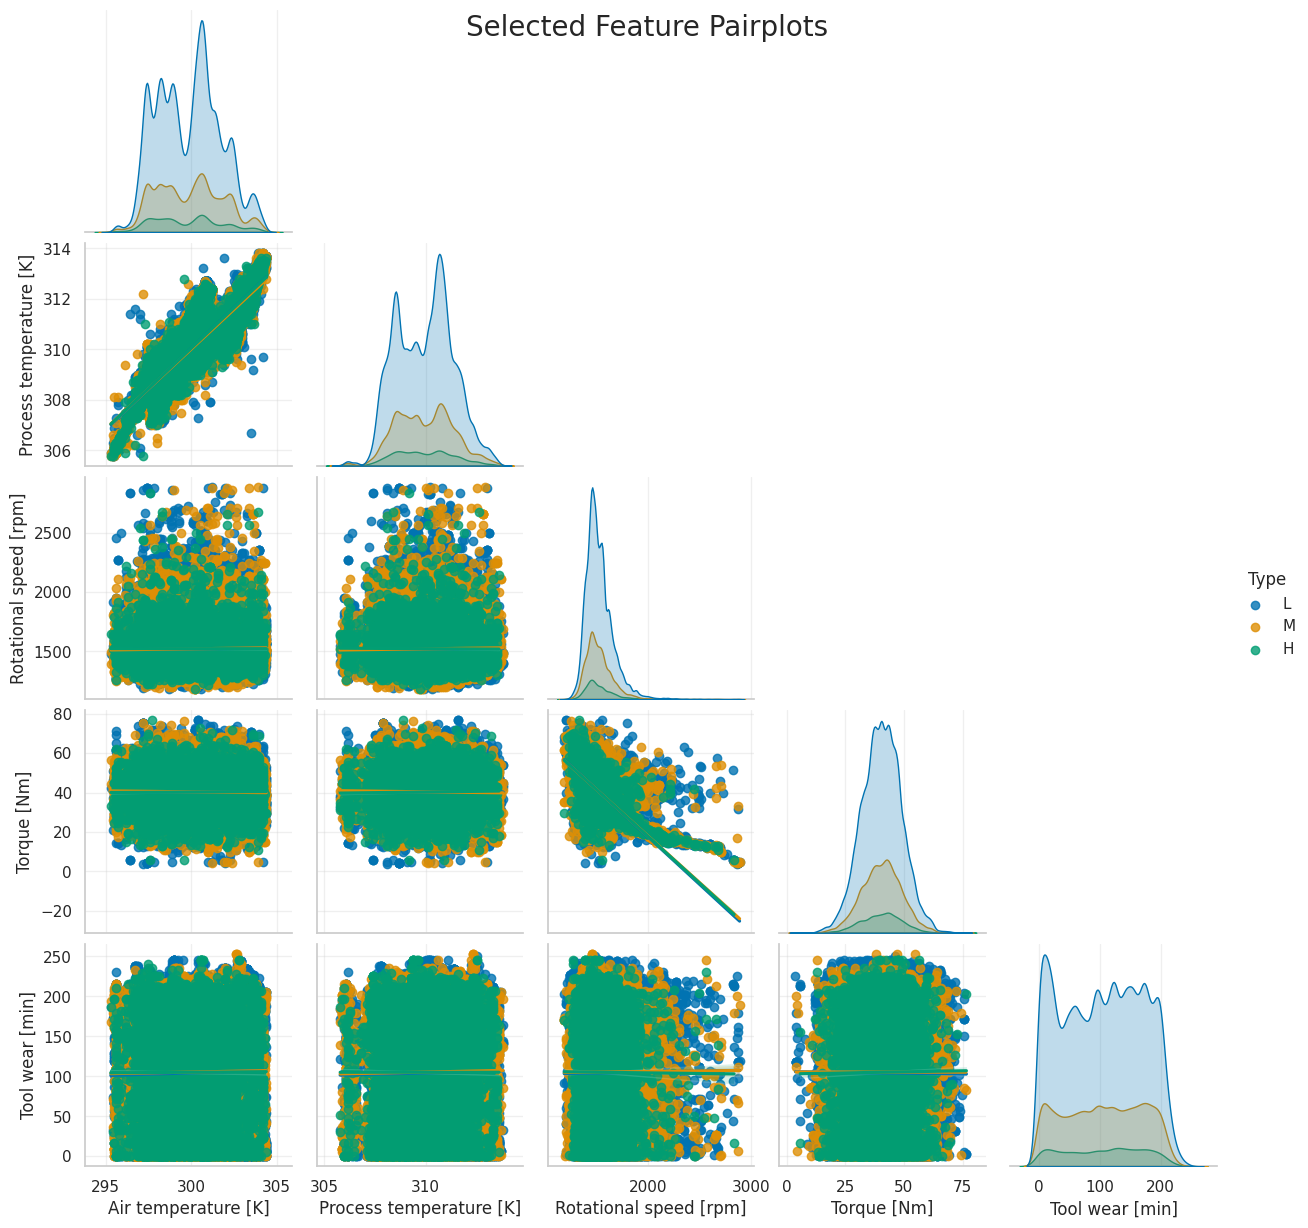

In [13]:
sns.pairplot(df[['Type', 
                'Air temperature [K]', 
                'Process temperature [K]',
                'Rotational speed [rpm]', 
                'Torque [Nm]', 
                'Tool wear [min]']],
             hue='Type',
             kind="reg",
             diag_kind='kde',
             corner=True)
plt.suptitle('Selected Feature Pairplots', fontsize=20)
plt.show()

<Axes: >

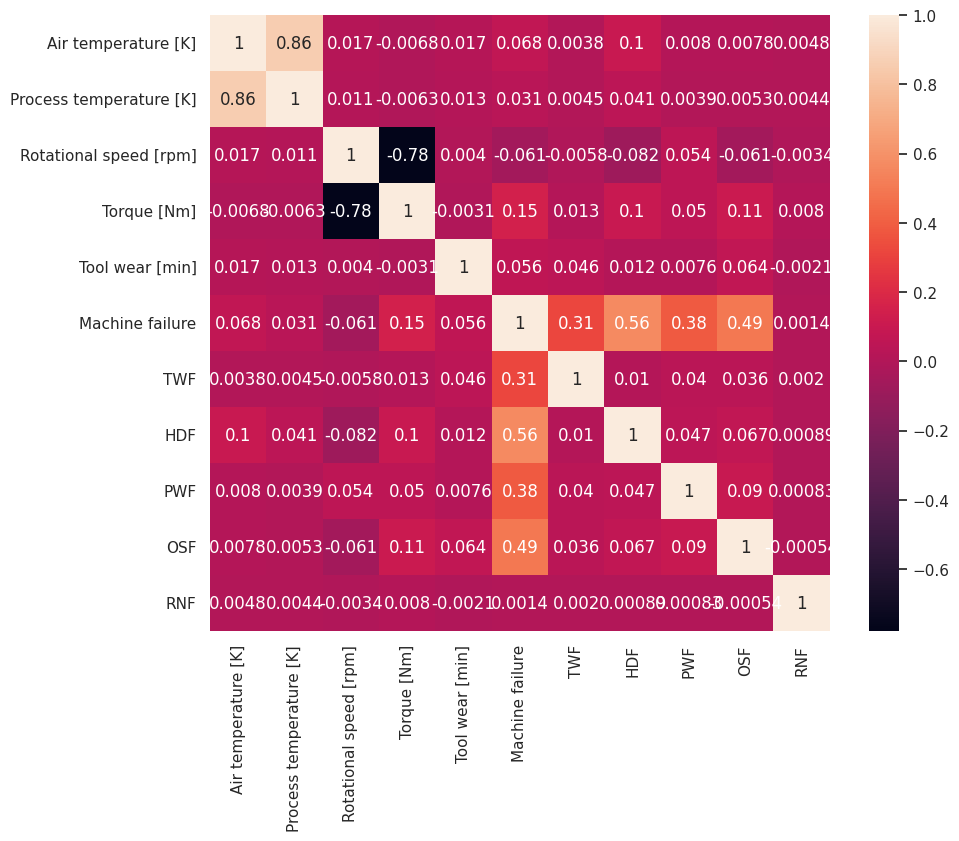

In [14]:
plt.figure(figsize=(10,8))
sns.heatmap(df.iloc[:,3:].corr(numeric_only=False), annot=True)

In [15]:
RAND_STATE = 42

In [42]:
# Countplot shows that the dataset is imbalanced (label 0 much more than label 1). Therefore, downsample
# label 0 data to match label 1's frequency.
# Occasionally, after running all the above EDA, the "Machine failure" column values seem to have changed to string
# type i.e. must check against values '0' and '1'. Not sure what caused it. The problem disappeared after reloading
# the csv file into dataframe.
class_0 = df[df['Machine failure'] == 0]
class_1 = df[df['Machine failure'] == 1]
class_0_dsampled = resample(class_0, replace=False, n_samples=len(class_1), random_state=RAND_STATE)
ddf = pd.concat([class_0_dsampled, class_1])

In [43]:
print(class_0.shape, class_1.shape)

(134281, 14) (2148, 14)


In [44]:
print("Original dataset size:", len(df))
print("Downsampled dataset size:", len(ddf))
print(ddf['Machine failure'].value_counts())

Original dataset size: 136429
Downsampled dataset size: 4296
Machine failure
0    2148
1    2148
Name: count, dtype: int64


In [45]:
X = ddf.drop(['id', 'Product ID', 'Machine failure'], axis=1)
y = ddf['Machine failure']

In [46]:
X = pd.get_dummies(X, drop_first=True, dtype='int')

In [47]:
X

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],TWF,HDF,PWF,OSF,RNF,Type_L,Type_M
21233,298.5,308.1,1396,39.9,20,0,0,0,0,0,1,0
109133,298.5,309.3,1605,40.1,131,0,0,0,0,0,1,0
41941,297.9,307.7,1615,39.5,69,0,0,0,0,0,0,1
121308,299.0,308.4,1535,47.5,153,0,0,0,0,1,0,1
79340,297.5,309.3,1372,29.8,72,0,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...
135902,302.6,312.1,1638,35.0,215,1,0,0,0,0,1,0
135917,297.3,308.2,1553,33.5,208,1,0,0,0,0,1,0
135957,299.1,310.6,1353,49.7,74,0,0,0,0,0,1,0
136053,302.4,312.0,1286,62.3,162,0,0,1,0,0,0,0


In [48]:
pl = Pipeline([
    ('scaler', MinMaxScaler()),           # MinMaxScaler is slightly better than StandardScaler for Logistic Regressor in this dataset
    ('transformer', PowerTransformer())   # Use this transform to minimise skewness in "Rotational Speed" feature
])
X = pl.fit_transform(X)
y = np.ravel(y)

In [49]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=RAND_STATE)

In [50]:
X_test[0]

array([ 1.04577508e+00,  1.31727829e+00,  5.09414619e-01, -1.23308262e-03,
       -1.73174796e-01, -2.27837425e-01, -4.40450525e-01, -2.85606367e-01,
       -3.77562169e-01, -5.29256124e-02,  6.20773358e-01, -5.33562550e-01])

In [51]:
# Define metric(s) to compare the models
metrics = ['ROC_AUC','Accuracy','Precision','Recall','F1-Score']

# Initialize DataFrame of model performance
performance = pd.DataFrame(columns=metrics)

In [52]:
# Logistic Regression
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)
y_pred_lr = lr.predict_proba(X_test)[:,1]
y_pred_lr2 = pd.DataFrame(y_pred_lr)[0].apply(lambda x: 1 if x >= 0.5 else 0)
lr_roc_auc = roc_auc_score(y_test, y_pred_lr)
accuracy = accuracy_score(y_test, y_pred_lr2)
cr = classification_report(y_test, y_pred_lr2, output_dict=True)
performance.loc['Logistic Regressor'] = {
    'ROC_AUC': lr_roc_auc,
    'Accuracy': accuracy,
    'Precision': cr['1']['precision'],
    'Recall': cr['1']['recall'],
    'F1-Score': cr['1']['f1-score'],
}

In [53]:
# Random Forest
rf = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=RAND_STATE)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict_proba(X_test)[:,1]
y_pred_rf2 = pd.DataFrame(y_pred_rf)[0].apply(lambda x: 1 if x >= 0.5 else 0)
rf_roc_auc = roc_auc_score(y_test, y_pred_rf)
accuracy = accuracy_score(y_test, y_pred_rf2)
cr = classification_report(y_test, y_pred_rf2, output_dict=True)
performance.loc['Random Forest'] = {
    'ROC_AUC': rf_roc_auc,
    'Accuracy': accuracy,
    'Precision': cr['1']['precision'],
    'Recall': cr['1']['recall'],
    'F1-Score': cr['1']['f1-score'],
}

In [54]:
accuracy

0.9188998589562765

In [55]:
cr['accuracy']

0.9188998589562765

In [56]:
# XGBoost
xgb = XGBClassifier(n_estimators=1000)
xgb.fit(X_train, y_train)
y_pred_xgb = xgb.predict_proba(X_test)[:,1]
y_pred_xgb2 = pd.DataFrame(y_pred_xgb)[0].apply(lambda x: 1 if x >= 0.5 else 0)
xgb_roc_auc = roc_auc_score(y_test, y_pred_xgb)
accuracy = accuracy_score(y_test, y_pred_xgb2)
cr = classification_report(y_test, y_pred_xgb2, output_dict=True)
performance.loc['XGB'] = {
    'ROC_AUC': xgb_roc_auc,
    'Accuracy': accuracy,
    'Precision': cr['1']['precision'],
    'Recall': cr['1']['recall'],
    'F1-Score': cr['1']['f1-score'],
}

In [57]:
# Tuned XGBoost

# Define a dictionary containing the parameters to tune
xgb_params = {
    'n_estimators': [5, 10, 50, 100, 500, 1000],
    'learning_rate': [0.005, 0.01, 0.05, 0.1, 0.2],
    'max_depth': [3, 5, 10, 20, 50],
}
xgbc = XGBClassifier(n_estimators=1000)
gs = GridSearchCV(xgbc, param_grid=xgb_params, scoring='roc_auc', cv=3, verbose=1)
gs.fit(X_train, y_train)
txgb = gs.best_estimator_
txgb_params = gs.best_params_
print('best xgboost params:', txgb_params)
y_pred_txgb = txgb.predict_proba(X_test)[:,1]
y_pred_txgb2 = pd.DataFrame(y_pred_txgb)[0].apply(lambda x: 1 if x >= 0.5 else 0)
txgb_roc_auc = roc_auc_score(y_test, y_pred_txgb)
accuracy = accuracy_score(y_test, y_pred_txgb2)
cr = classification_report(y_test, y_pred_txgb2, output_dict=True)
performance.loc['Tuned XGB'] = {
    'ROC_AUC': txgb_roc_auc,
    'Accuracy': accuracy,
    'Precision': cr['1']['precision'],
    'Recall': cr['1']['recall'],
    'F1-Score': cr['1']['f1-score'],
}
import joblib
joblib.dump(txgb, 'xgb.pkl')

Fitting 3 folds for each of 150 candidates, totalling 450 fits
best xgboost params: {'learning_rate': 0.01, 'max_depth': 5, 'n_estimators': 500}


['xgb.pkl']

### FNN model

In [60]:
tf.random.set_seed(RAND_STATE)
fnn = Sequential()
fnn.add(Input((12,)))
fnn.add(Dense(64, activation='relu'))
# fnn.add(Dropout(0.3))
fnn.add(Dense(32, activation='relu'))
# fnn.add(Dropout(0.3))
fnn.add(Dense(16, activation='relu'))
fnn.add(Dense(8, activation='relu'))
fnn.add(Dense(1, activation='sigmoid'))
fnn.compile(optimizer=Adam(), loss=BinaryCrossentropy(from_logits=False), metrics=['accuracy', 'precision', 'recall', 'f1_score'])
es = EarlyStopping(patience=5, mode='min')
fnn.fit(X_train, pd.DataFrame(y_train), epochs=20, validation_data=(X_test, pd.DataFrame(y_test)), callbacks=[es])

Epoch 1/20


2026-09-03 14:51:45.593853: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:465] Loaded cuDNN version 8907


81/90 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7130 - f1_score: 0.6769 - loss: 0.5201 - precision: 0.6684 - recall: 0.9422

I0000 00:00:1788411106.476706   48780 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


90/90 ━━━━━━━━━━━━━━━━━━━━ 5s 31ms/step - accuracy: 0.8235 - f1_score: 0.6759 - loss: 0.4123 - precision: 0.7986 - recall: 0.8747 - val_accuracy: 0.9111 - val_f1_score: 0.6476 - val_loss: 0.2685 - val_precision: 0.9525 - val_recall: 0.8571
Epoch 2/20
90/90 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8978 - f1_score: 0.6759 - loss: 0.2610 - precision: 0.9659 - recall: 0.8291 - val_accuracy: 0.9104 - val_f1_score: 0.6476 - val_loss: 0.2361 - val_precision: 0.9510 - val_recall: 0.8571
Epoch 3/20
90/90 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9003 - f1_score: 0.6759 - loss: 0.2452 - precision: 0.9603 - recall: 0.8393 - val_accuracy: 0.9104 - val_f1_score: 0.6476 - val_loss: 0.2316 - val_precision: 0.9510 - val_recall: 0.8571
Epoch 4/20
90/90 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9017 - f1_score: 0.6759 - loss: 0.2360 - precision: 0.9611 - recall: 0.8414 - val_accuracy: 0.9140 - val_f1_score: 0.6476 - val_loss: 0.2269 - val_precision: 0.9485 - val_recall: 0.8675
Epoch 5/20

<Axes: >

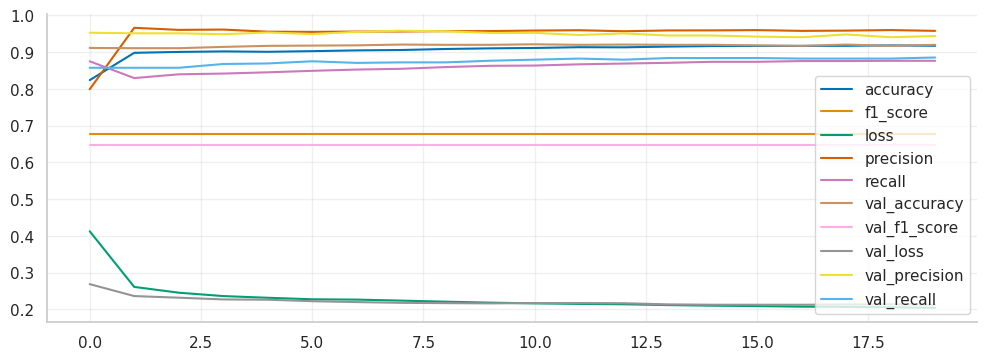

In [61]:
pd.DataFrame(fnn.history.history).plot()

In [64]:
y_pred_fnn = fnn.predict(X_test)
y_pred_fnn = pd.DataFrame(y_pred_fnn[:,0])[0].apply(lambda x: 1 if x >= 0.5 else 0)
fnn.evaluate(X_test, pd.DataFrame((y_test)))
fnn_roc_auc = roc_auc_score(pd.DataFrame(y_test), y_pred_fnn)
accuracy = accuracy_score(pd.DataFrame(y_test), y_pred_fnn)
cr = classification_report(pd.DataFrame(y_test), y_pred_fnn, output_dict=True)
performance.loc['FNN'] = {
    'ROC_AUC': fnn_roc_auc,
    'Accuracy': accuracy,
    'Precision': cr['1']['precision'],
    'Recall': cr['1']['recall'],
    'F1-Score': cr['1']['f1-score'],
}

45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9196 - f1_score: 0.6476 - loss: 0.2126 - precision: 0.9435 - recall: 0.8851


In [65]:
bag = BaggingClassifier(estimator=DecisionTreeClassifier(), n_estimators=5, random_state=RAND_STATE)
bag.fit(X_train,y_train)
y_pred_p_bag = bag.predict_proba(X_test)[:,1]
y_pred_bag = bag.predict(X_test)
bag_roc_auc = roc_auc_score(y_test, y_pred_p_bag)
accuracy = accuracy_score(y_test, y_pred_bag)
cr = classification_report(y_test, y_pred_bag, output_dict=True)
performance.loc['Bagging/DecisionTree'] = {
    'ROC_AUC': bag_roc_auc,
    'Accuracy': accuracy,
    'Precision': cr['1']['precision'],
    'Recall': cr['1']['recall'],
    'F1-Score': cr['1']['f1-score'],
}

In [66]:
perf = pd.DataFrame(performance).sort_values(['Recall'], ascending=False)
perf

,ROC_AUC,Accuracy,Precision,Recall,F1-Score
Random Forest,0.966777,0.918900,0.935185,0.892489,0.913338
XGB,0.957311,0.893512,0.885965,0.892489,0.889215
Bagging/DecisionTree,0.942175,0.902680,0.907994,0.886598,0.897168
FNN,0.918205,0.919605,0.943485,0.885125,0.913374
Tuned XGB,0.967448,0.916784,0.948800,0.873343,0.909509
Logistic Regressor,0.946367,0.915374,0.987784,0.833579,0.904153


In [67]:
perf.reset_index(names=['model_name'])

,model_name,ROC_AUC,Accuracy,Precision,Recall,F1-Score
0,Random Forest,0.966777,0.918900,0.935185,0.892489,0.913338
1,XGB,0.957311,0.893512,0.885965,0.892489,0.889215
2,Bagging/DecisionTree,0.942175,0.902680,0.907994,0.886598,0.897168
3,FNN,0.918205,0.919605,0.943485,0.885125,0.913374
4,Tuned XGB,0.967448,0.916784,0.948800,0.873343,0.909509
5,Logistic Regressor,0.946367,0.915374,0.987784,0.833579,0.904153


In [68]:
perf.reset_index(names=['model_name']).to_csv('perf.csv', index=False)

In [69]:
perf2 = pd.read_csv('perf.csv')
perf2

,model_name,ROC_AUC,Accuracy,Precision,Recall,F1-Score
0,Random Forest,0.966777,0.918900,0.935185,0.892489,0.913338
1,XGB,0.957311,0.893512,0.885965,0.892489,0.889215
2,Bagging/DecisionTree,0.942175,0.902680,0.907994,0.886598,0.897168
3,FNN,0.918205,0.919605,0.943485,0.885125,0.913374
4,Tuned XGB,0.967448,0.916784,0.948800,0.873343,0.909509
5,Logistic Regressor,0.946367,0.915374,0.987784,0.833579,0.904153


In [70]:
best_perf_by_metric = {}
for metric in perf.columns.tolist():
    best_perf_by_metric[metric] = perf[metric].idxmax()
pd.DataFrame([best_perf_by_metric])

,ROC_AUC,Accuracy,Precision,Recall,F1-Score
0,Tuned XGB,FNN,Logistic Regressor,Random Forest,FNN


In [71]:
best_perf_by_metric['Recall']

'Random Forest'

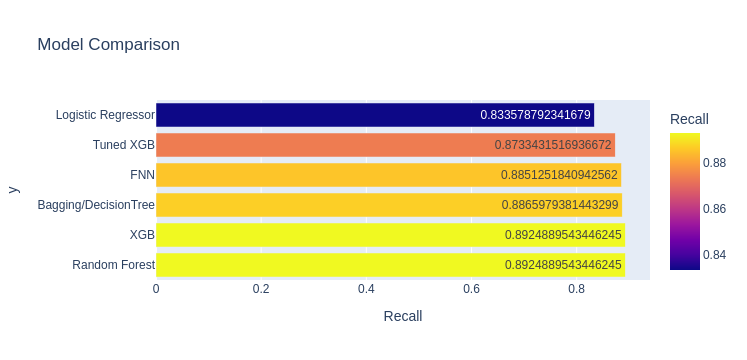

<Figure size 600x300 with 0 Axes>

In [72]:
# Compare models

# Sort dataframe by the metric
performance.sort_values('Recall', ascending=False, inplace=True)

# Plot model metrics

plt.figure(figsize=(6,3))

# Using seaborn to plot
# ax = sns.barplot(data=performance, x='ROC_AUC', y=performance.index.tolist())
# # Add data labels to the bars
# for i, v in enumerate(performance['AUC_ROC']):
#     ax.text(v + 0.02, i, str(round(v, 4)))
# ax.set_title('Model Comparison')
# plt.tight_layout()

# Using plotly express to plot
px.bar(data_frame=perf, x='Recall', y=perf.index.tolist(), width=600,
       text='Recall', title='Model Comparison', color='Recall')


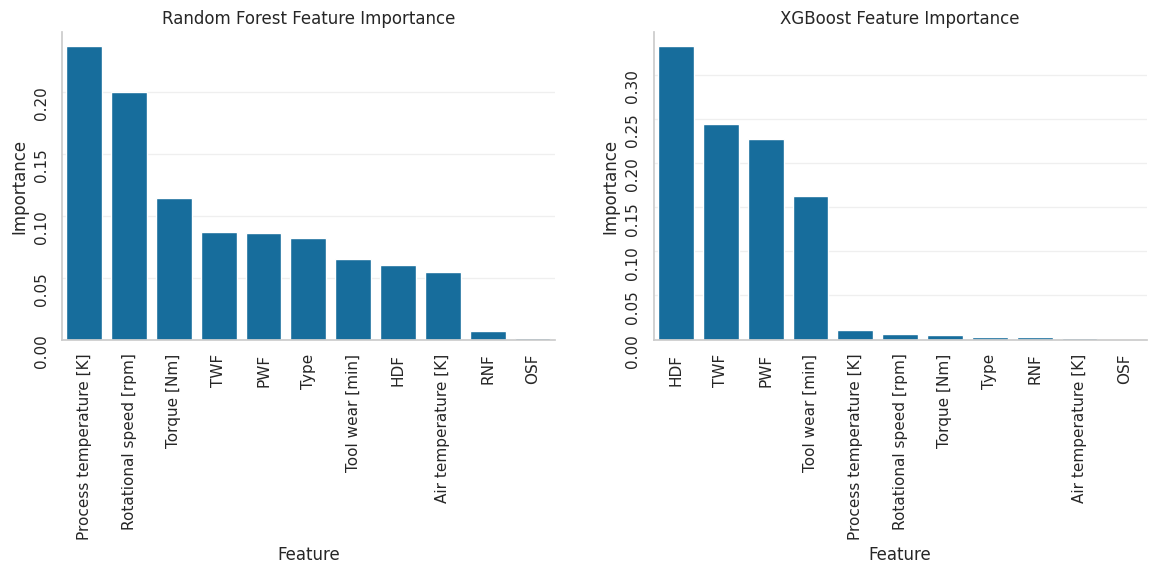

In [73]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(14, 4))

# Compute the feature importance for Random Forest
importances_rf = sorted(list(zip(df.drop(['id', 'Product ID', 'Machine failure'], axis=1).columns,
                              rf.feature_importances_)))

# Transform it into a DataFrame
importances_rf_df = pd.DataFrame(importances_rf, columns= ['Feature', 'Importance'])

# Sorting importances
importances_rf_df = importances_rf_df.sort_values(['Importance'], ascending=False).reset_index(drop=True)

# Plot the feature importance
ax[0] = sns.barplot(data=importances_rf_df, x='Feature', y='Importance', ax=ax[0])
ax[0].set_title('Random Forest Feature Importance')
ax[0].tick_params(labelrotation=90)


# Compute the feature importance for XGBoost
# first arg to zip should have been xgb.feature_names_in_ but there is an error ...
importances_xgb = sorted(list(zip(df.drop(['id', 'Product ID', 'Machine failure'], axis=1).columns,
                              xgb.feature_importances_)))

# Transform it into a DataFrame
importances_xgb_df = pd.DataFrame(importances_xgb, columns= ['Feature', 'Importance'])

# Sorting importances
importances_xgb_df = importances_xgb_df.sort_values(['Importance'], ascending=False).reset_index(drop=True)

# Plot the feature importance
ax[1] = sns.barplot(data=importances_xgb_df, x='Feature', y='Importance', ax=ax[1])
ax[1].set_title('XGBoost Feature Importance')
ax[1].tick_params(labelrotation=90)

plt.show()
